Importing ORM utilities and declaring entities:

In [1]:
from pyutil.entities import *

Write the path to your database file in the `.env` file

In [2]:
from os import getenv
from dotenv import load_dotenv

_ = load_dotenv()
db_file = getenv('COMMON_DB_FILE')

Creating a session from the given file:

In [12]:
from sqlalchemy import create_engine
from sqlalchemy.orm import Session

eng = create_engine(f'sqlite:///{db_file}')
Base.metadata.create_all(eng)
session = Session(eng)

Assigning colors to statuses for charts:

In [4]:
from sqlalchemy import select

status_color: dict[NormalisedStatus, str] = {
  NormalisedStatus.accepted: '#3bcc56',
  NormalisedStatus.rejected: '#db1717',
  NormalisedStatus.draft: 'yellow',
  NormalisedStatus.review: '#3b93cc',
  NormalisedStatus.withdrawn: 'orange',
  NormalisedStatus.superseded: '#802be0',
  NormalisedStatus.unknown: 'gray'
}

In [13]:
from collections import Counter
from matplotlib import pyplot as plt

# Plots the latest statuses of the given proposals as a pie chart
def pie_status(proposal_ids: list[tuple[int, str]], title: str):
  status_counts: Counter[NormalisedStatus] = Counter()
  for proj_id, prop_id in proposal_ids:
    latest_status = session.scalar(select(ProposalStatus.normalised_status)
      .where(ProposalStatus.project_id.is_(proj_id))
      .where(ProposalStatus.proposal_id.is_(prop_id))
      .order_by(ProposalStatus.status_index.desc())
      .limit(1))
    if latest_status:
      status_counts[latest_status] += 1
  # status_stats[project.enhancement_proposal_name] = status_counts
  status_counts_ord = status_counts.most_common()

  plt.title(f'{title} ({status_counts.total()} samples)')
  plt.pie([s[1] for s in status_counts_ord],
    labels=[s[0].value for s in status_counts_ord],
    colors=[status_color[s[0]] for s in status_counts_ord],
    autopct='%1.1f%%')

Computing the proportions of each status, within each project (only considering most recent status):

Current status proportions:


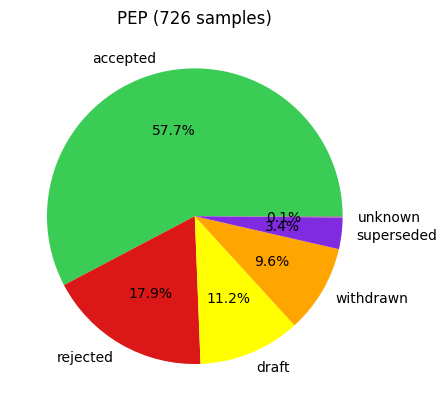

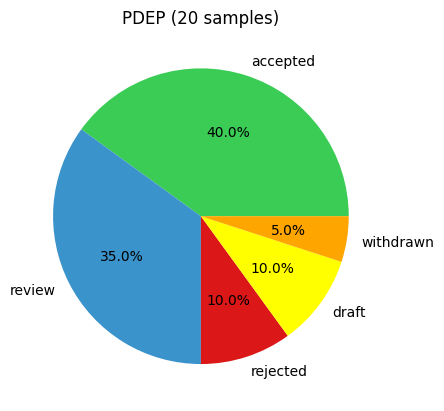

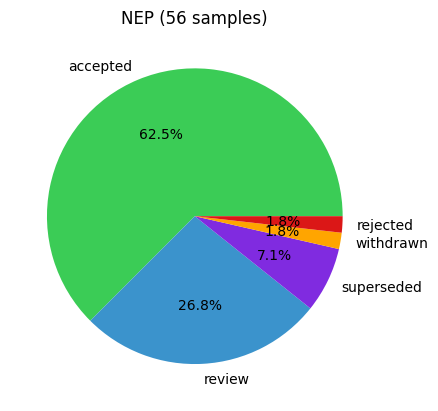

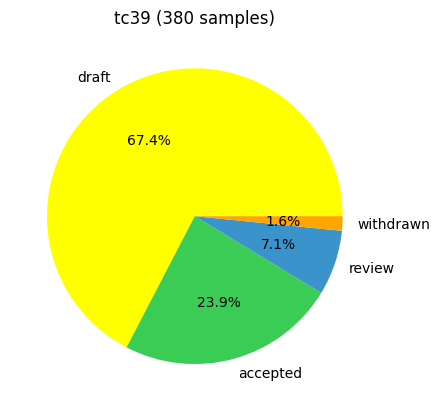

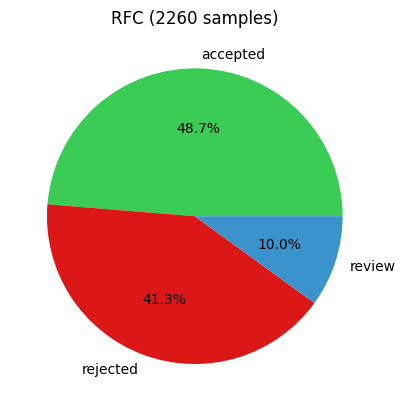

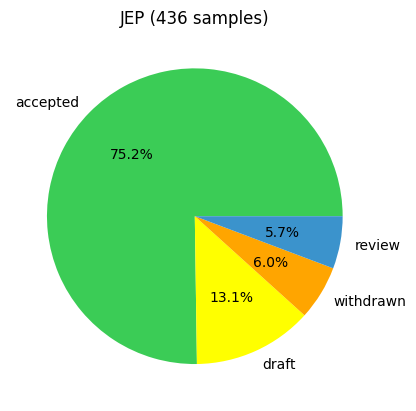

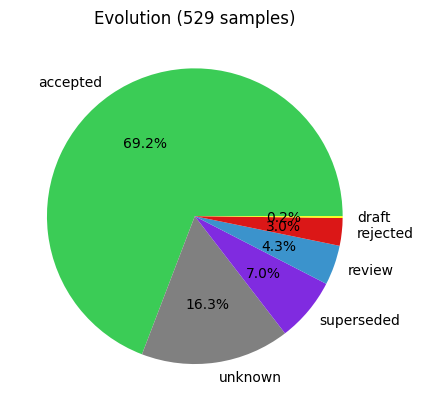

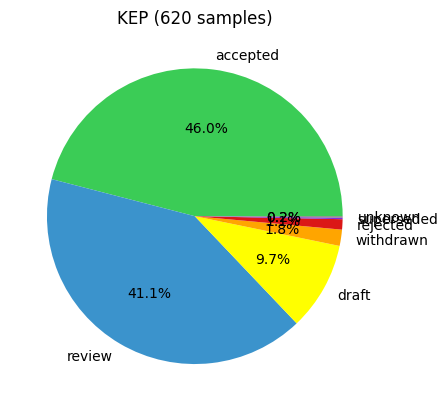

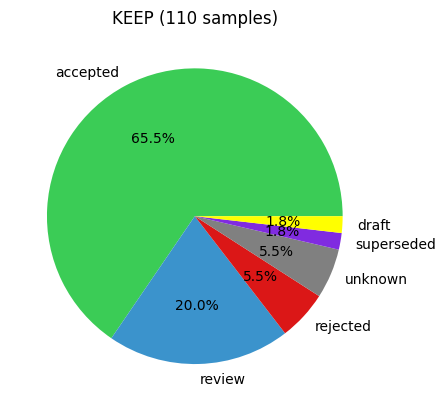

In [14]:
projects = list(session.scalars(select(Project)))

print('Current status proportions:')
for i, project in enumerate(projects):
  prop_ids = list(session.scalars(select(Proposal.proposal_id).where(Proposal.project_id.is_(project.project_id))))

  # plt.subplot(len(projects), 1, i+1)
  pie_status(
    [(project.project_id, prop_id) for prop_id in prop_ids],
    project.enhancement_proposal_name)
  plt.show()

Picking the most popular proposals in each project, for me to manually read through and discover traits:

In [ ]:
from sqlalchemy import func

num_to_take = 5

print('By number of comments:')
for project in projects:
  most_comments = session.scalars(select(Proposal.proposal_id)
    .join(Comment, onclause=Proposal.project_id.is_(Comment.project_id) & Proposal.proposal_id.is_(Comment.proposal_id))
    .where(Proposal.project_id.is_(project.project_id))
    .group_by(Proposal.proposal_id)
    .order_by(func.count(Comment.comment_id).desc())
    .limit(num_to_take))
  print(f'{project.enhancement_proposal_name}: {list(most_comments)}')

print('By number of revisions:')
for project in projects:
  most_comments = session.scalars(select(Proposal.proposal_id)
    .join(ProposalRevision)
    .where(Proposal.project_id.is_(project.project_id))
    .group_by(Proposal.proposal_id)
    .order_by(func.count(ProposalRevision.revision_index).desc())
    .limit(num_to_take))
  print(f'{project.enhancement_proposal_name}: {list(most_comments)}')

By number of comments:
PEP: ['8', '572', '517', '318', '426']
PDEP: []
NEP: ['14', '18', '20', '17', '41']
tc39: ['ShadowRealm', 'Updates to Tail Calls to include an explicit syntactic opt-in', 'Record & Tuple', 'Import Attributes', 'Temporal']
RFC: ['0078', '0148', '0219', '0235', '0439']
JEP: ['331', '472', '450', '537', '223']
KEP: ['4381', '3063', '4671', '3488', '127']
KEEP: ['0367', '0259', '0427', '0441', '0075']
By number of revisions:
PEP: ['11', '101', '1', '596', '619']
PDEP: ['1-1', '6-1', '10-1', '14-1', '12-1']
NEP: ['50', '35', '29', '18', '0']
tc39: ['Array.fromAsync', 'BigInt Math', 'Call-this operator', 'Bind-this operator', 'Pattern Matching']
RFC: ['3878', '3537', '2682', '2456', '2299']
JEP: ['537', '533', '506', '454', '532']
KEP: ['1287', '3488', '4603', '1040', '116']
KEEP: ['0367', '0455', '0452', '0430', '0104']


Below are the manually identified topics from the proposals above:

In [ ]:
sep_topics = {
  2: {
    14: ['deprecation'],
    18: ['internal'],
    20: ['syntax'],
    17: ['api structure'],
    41: ['types', 'syntax'],
    50: ['types', 'dev experience'],
    35: ['api structure', 'internal'],
    29: ['versioning'],
    0: ['meta'],
  },
  6: {
    331: ['performance', 'api structure'],
    472: ['dev experience'],
    450: ['performance', 'memory'],
    537: ['api structure'],
    223: ['versioning', 'dev experience', 'api structure'],
    533: ['concurrency', 'api structure'],
    506: ['api structure', 'performance'],
    454: ['memory', 'api structure'],
    352: ['syntax'],
  }
}